# Practice PS07: Outlier analysis

The objective of this session is to practice finding outliers by implementing the [Isolation Forest](https://en.wikipedia.org/wiki/Isolation_forest) algorithm.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

Author: <font color="#2680EB">Andrés Cózar Bolaños</font>

E-mail: <font color="#2680EB">andres.cozar01@estudiant.upf.edu</font>

AI used: <font color="#2680EB">Chat GPT</font>

Date: <font color="#2680EB">09/11/2026</font>

In [141]:
# LEAVE THIS CELL AS-IS
import csv
import io
import random

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

# 0. Dataset

In [81]:
# LEAVE AS-IS

# Load both datasets
dft = pd.read_csv('data/annthyroid/annthyroid.csv', sep=',')
dfc = pd.read_csv('data/cardiotocography/cardio.csv', sep=',')
dfb = pd.read_csv('data/breastcancer/breast_cancer.csv', sep=',')

In [82]:
# AI: Correct column names
dft.columns = ['age', 'tsh', 't3', 't4_thyroxine', 'free_thyroxine_index', 'thyroid_binding_globulin', 'result']

dfc.columns = ['LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV', 'MLTV', 'width', 'min', 'max', 'nmax', 'nzeros', 'mode', 'mean', 'median', 'variance', 'tendency', 'result']

dfb.columns = ['sample_id', 'clump_thickness', 'uniformity_cell_size', 'uniformity_cell_shape', 'marginal_adhesion', 'single_epithelial_cell_size', 'bare_nuclei', 'bland_chromatin', 'normal_nucleoli', 'mitoses', 'result']

# 1. Exploratory analysis

In [83]:
# LEAVE AS-IS

def print_normal_abnormal(df, dataset_name):
    print(f"The {dataset_name} dataset contains {len(df)} patients")
    n_normal = len(df[df['result'] == 'normal'])
    n_abnormal = len(df[df['result'] == 'abnormal'])
    print(" Normal   : %d (%.2f%%)" % ( n_normal, 100*n_normal / (n_normal + n_abnormal)))
    print(" Abnormal : %d (%.2f%%)" % ( n_abnormal, 100*n_abnormal / (n_normal + n_abnormal)))
    print()
    
print_normal_abnormal(dft, "Thyroid")
print_normal_abnormal(dfc, "Cardiotocography")
print_normal_abnormal(dfb, "Breast Cancer")

The Thyroid dataset contains 7200 patients
 Normal   : 6666 (92.58%)
 Abnormal : 534 (7.42%)

The Cardiotocography dataset contains 1831 patients
 Normal   : 1655 (90.39%)
 Abnormal : 176 (9.61%)

The Breast Cancer dataset contains 699 patients
 Normal   : 458 (65.52%)
 Abnormal : 241 (34.48%)



## 1.1. Visual inspection for class separation <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement a function to display scatter plots for every pair of features.**</font>

In [84]:

def print_scatter_matrix(dataset, dataset_name, color_normal, color_abnormal):
    print(f"Scatter matrix for the {dataset_name} dataset.")

    # YOUR ANSWER HERE
    color_code = {'abnormal': color_abnormal, 'normal': color_normal}
    sns.pairplot(dataset, hue='result', palette=color_code)

Scatter matrix for the Thyroid dataset.
Scatter matrix for the Breast cancer dataset.


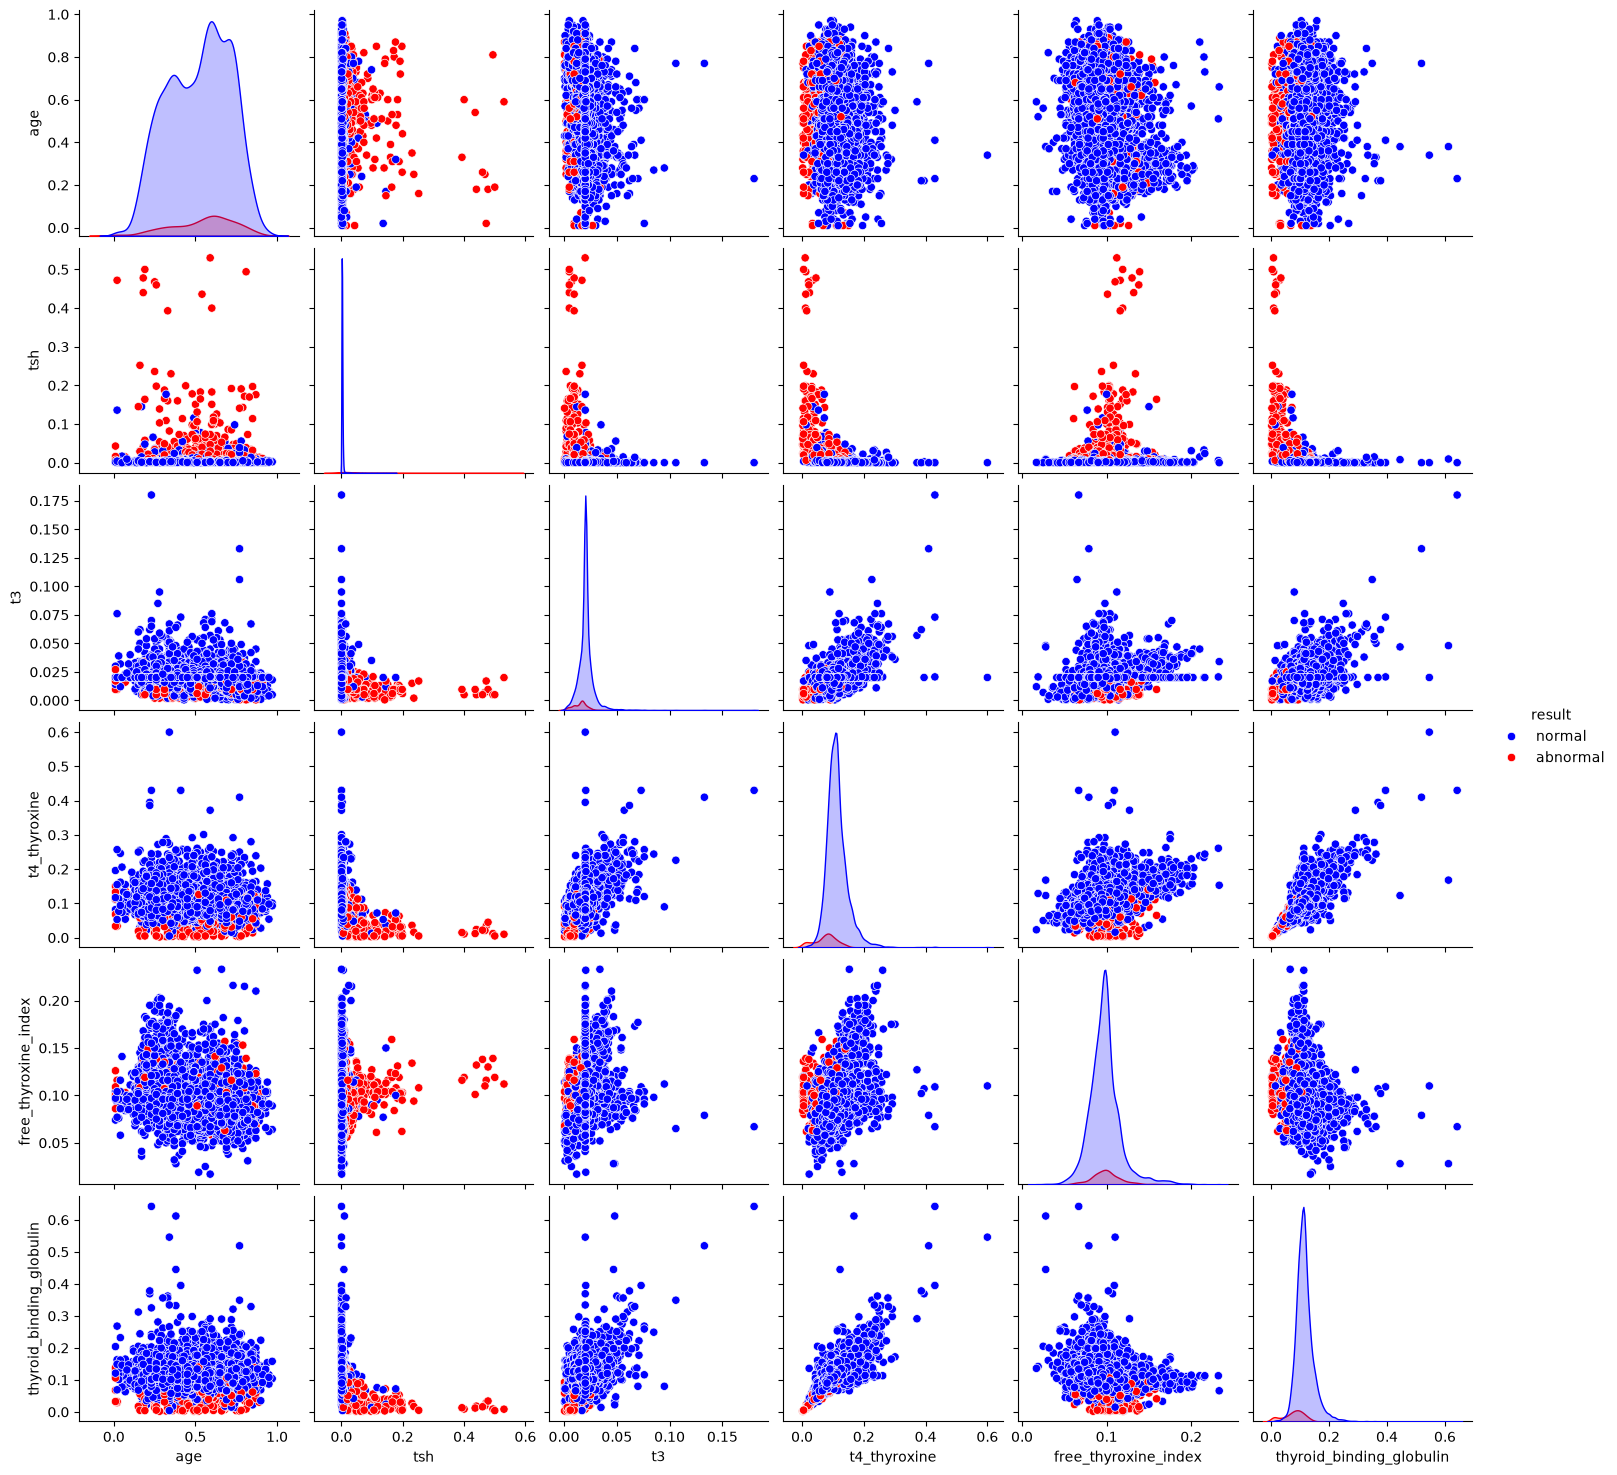

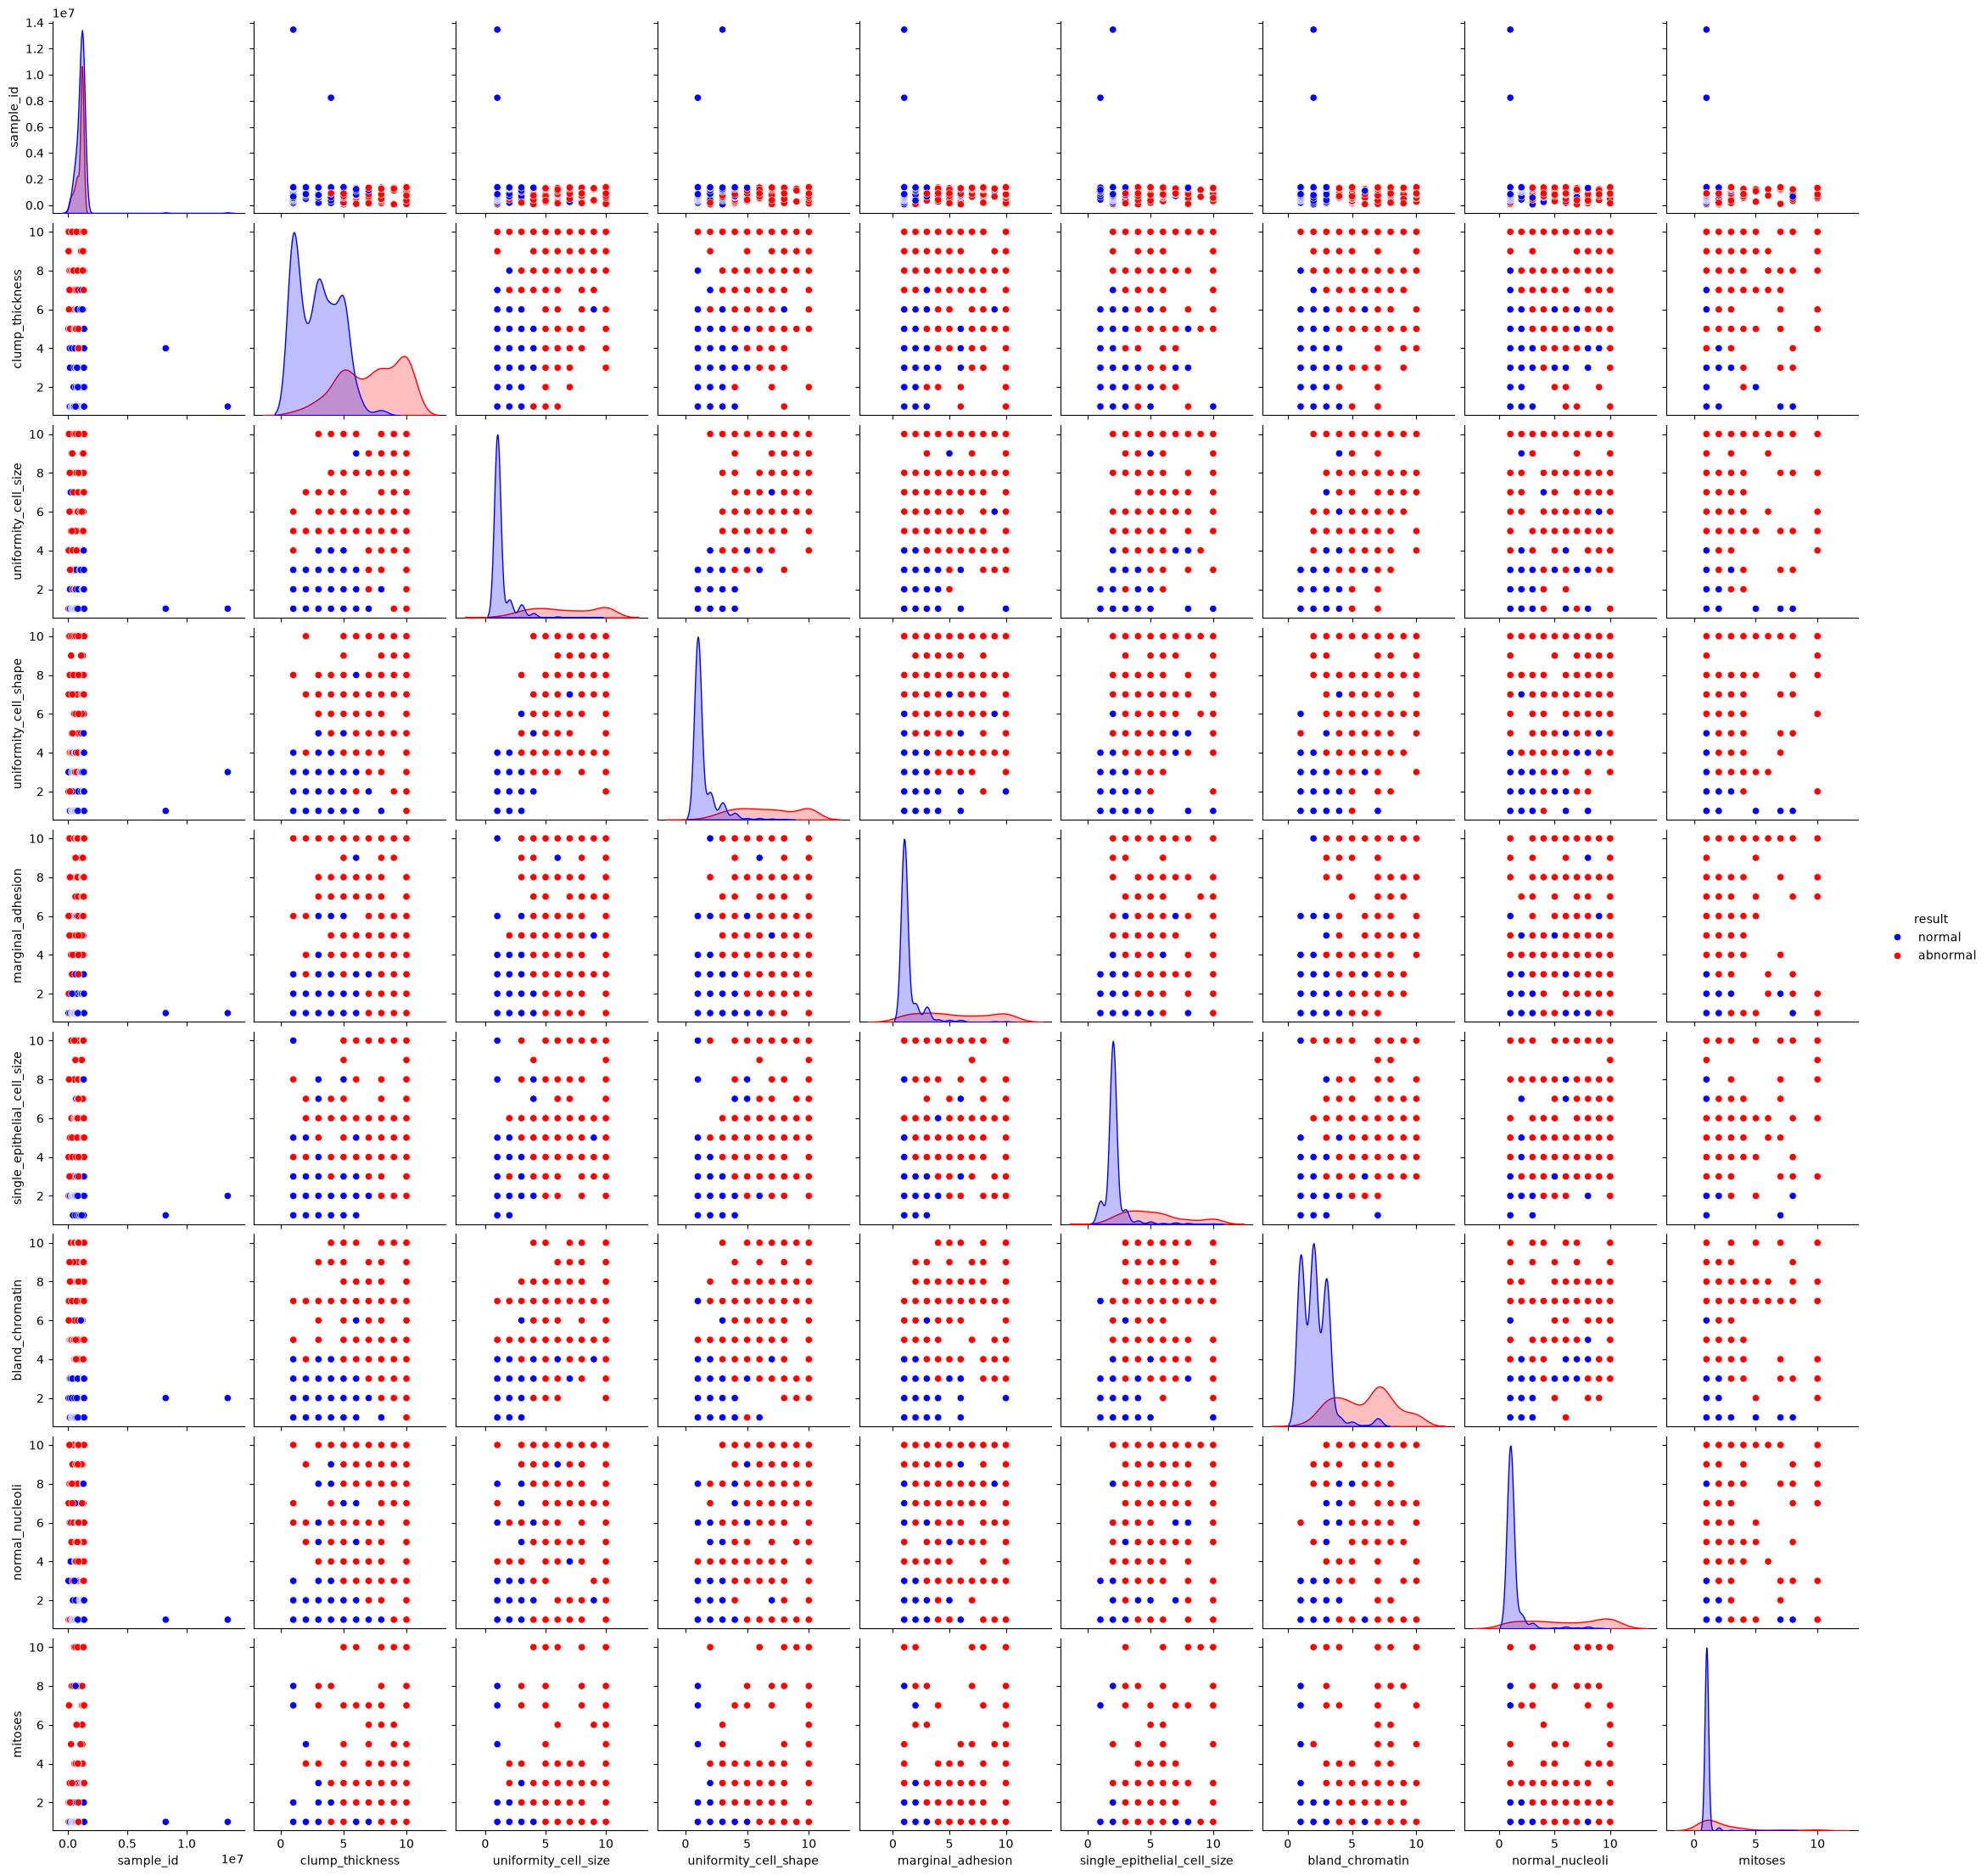

In [85]:
# LEAVE AS-IS

print_scatter_matrix(dft, 'Thyroid', 'blue', 'red')
print_scatter_matrix(dfb, 'Breast cancer', 'blue', 'red')

<font size="+1" color="#2680EB">**Examine the scatter plots of combinations of two features.** Answer these questions.</font>

**Answer:**

What do the plots in the diagonal represent?

* They show the distribution of each feature separately for normal and abnormal cases.

In the case of the *Thyroid* dataset, is there any single feature that provides good separation between classes, which one (if any)? Are there pairs of features that can do this to some extent? Can you provide an example of such pair of features? In each case (single feature and pair of features), is there complete separability, or some overlap?

* The tsh feature helps separate normal and abnormal cases. The pair tsh and t4_thyroxine also shows some separation, but there is still overlap between the classes.

And in the case of the *Breast cancer* dataset?

* Clump thickness and uniformity_cell_size separate the classes quite well, especially when combined. However, there is still some overlap.

In the *Breast cancer* dataset, many scatterplots look like a grid/lattice, why do you think that happens?

* Because most features have discrete integer values, the points appear in fixed positions, forming a grid.

## 1.2. Visual inspection for outliers  <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement a function that uses PCA to project into two dimensions.** The function should project all features except the last one, which contains the result (normal or abnormal).</font>

In [ ]:
def project_2D(df):

    # Extract features, which appear in all columns except the last one
    features = df.iloc[:, :-1]
    
    # Extract the last column, which contains the label
    result = df.iloc[:, -1]
    
    # Replace '?' values (present in one of the datasets) with NULL
    features = features.replace('?', np.nan)
    result = result.replace('?', np.nan)

    # Remove rows with NaN values in the features or the result
    valid_rows = features.notnull().all(axis=1) & result.notnull()
    features = features[valid_rows]
    result = result[valid_rows]
    
    # Apply PCA to project to 2 dimensions
    # Create output dataframe with projected dimensions named X and Y and the result

    # YOUR CODE HERE
    # AI edited: AI helped me with the PCA fit_transform part.
    projected = PCA(n_components=2).fit_transform(features)
    output = pd.DataFrame(projected, columns=['X', 'Y'])
    output['result'] = result.to_numpy()
    
    return output

<font size="+1" color="#2680EB">**Plot the projected datasets.** Reuse the color mapping you defined above.</font>

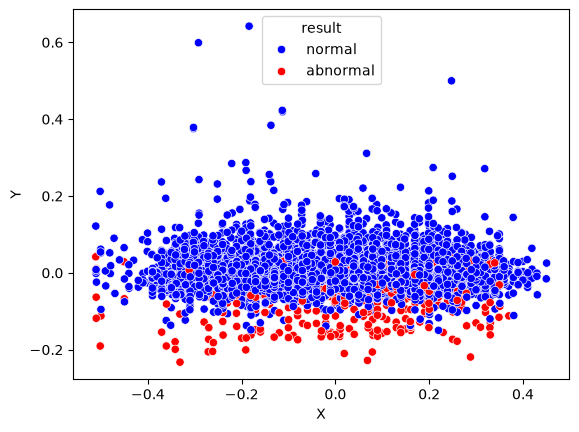

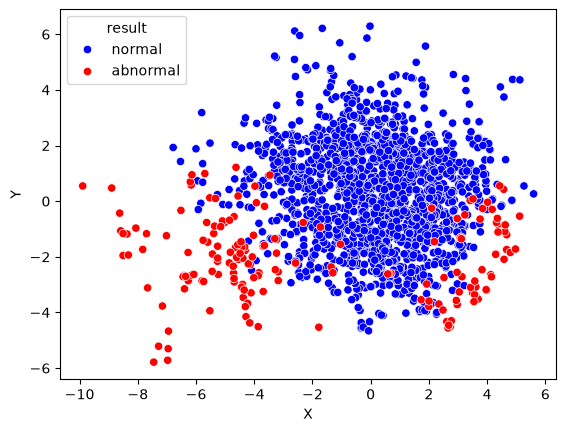

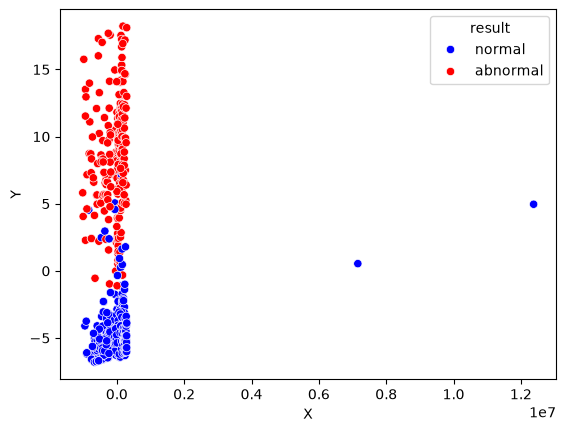

In [87]:
def plot_projected_dataset(dataset, dataset_name, color_normal, color_abnormal):
    df_projected = project_2D(dataset)

    # Create a color palette
    color_code = {'normal': color_normal, 'abnormal': color_abnormal}

    # Plot a scatter plot of df_projected with X on the x-axis and Y on the y-axis
    # Color points by the result column using seaborn
    # YOUR CODE HERE
    sns.scatterplot(data=df_projected, x='X', y='Y', hue='result', palette=color_code)
    plt.show()

plot_projected_dataset(dft, 'Thyroid', 'blue', 'red')
plot_projected_dataset(dfc, 'Cardiotocography', 'blue', 'red')
plot_projected_dataset(dfb, 'Breast cancer', 'blue', 'red')

<font size="+1" color="#2680EB">**Examine the scatter plots of the projected datasets.** Answer these questions.</font>

**Answer:**

In the case of the *Thyroid* dataset, would you say that the abnormal points are *outliers*? Are they extreme values? Briefly justify your answer.

* Yes, most abnormal points can be considered outliers because they are mostly below the normal points. However, they are not extreme values, since there is some overlap.

And in the case of the *Cardiotocography* dataset?

* Yes, some abnormal points are outliers because they are far from the normal group. Some are extreme values, but others overlap with normal points.

And in the case of the *Breast cancer* dataset?

* The abnormal points are mostly separated from the normal ones, especially along the Y-axis. However, there is some overlap, so not all abnormal points are outliers.

<font size="+1" color="#2680EB">**Repeat the analysis dropping the "sample_id" feature.**</font>

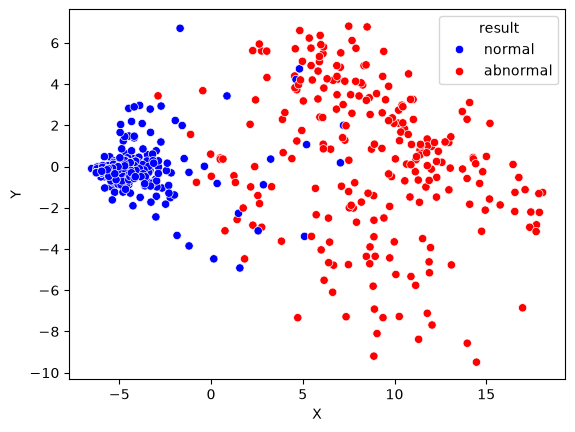

In [88]:
# YOUR ANSWER HERE
# dfb_noid = ...
dfb_noid = dfb.drop(columns=['sample_id'])
plot_projected_dataset(dfb_noid, 'Breast cancer', 'blue', 'red')

<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Answer:**

What happened when you removed the sample_id feature from the breast cancer dataset?

* The two classes are much better separated. Normal points are mostly on the left and abnormal points on the right, with some overlap.

Are the abnormal data points outliers? Are they extreme values?

* Yes, most abnormal points are far from the normal group, so they can be considered outliers. However, not all are extreme values because some overlap with normal points.

# 2. Create isolation tree

## 2.1. Random dimension and random split  <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement pick_random_dimension.**</font>

In [89]:
def pick_random_dimension(df, columns_to_ignore):
    # YOUR ANSWER HERE
    columns = [col for col in df.columns if col not in columns_to_ignore]
    return random.choice(columns)


In [90]:
# LEAVE AS-IS

print("Random dimensions for the 'thyroid' dataset")
print(pick_random_dimension(dft, ["result"]))
print(pick_random_dimension(dft, ["result"]))
print()

print("Random dimensions for the 'cardio' dataset")
print(pick_random_dimension(dfc, ["result"]))
print(pick_random_dimension(dfc, ["result"]))
print()

print("Random dimensions for the 'breast cancer' dataset")
print(pick_random_dimension(dfb, ["result", "sample_id"]))
print(pick_random_dimension(dfb, ["result", "sample_id"]))
print()

Random dimensions for the 'thyroid' dataset
t3
t3

Random dimensions for the 'cardio' dataset
FM
FM

Random dimensions for the 'breast cancer' dataset
clump_thickness
single_epithelial_cell_size




<font size="+1" color="#2680EB">**Implement pick_random_split.** It should return a random split point chosen uniformly at random between the minimum and the maximum value along a dimension.</font>

In [126]:
def pick_random_split(df, dimension):
    split_point = random.uniform(df[dimension].min(), df[dimension].max())
    return split_point

In [129]:
# LEAVE AS-IS

print("Random splits according to 't3' in the 'thyroid' dataset")
print(pick_random_split(dft, "t3"))
print(pick_random_split(dft, "t3"))
print()

print("Random splits according to 'AC' in the 'cardio' dataset")
print(pick_random_split(dfc, "AC"))
print(pick_random_split(dfc, "AC"))
print()

print("Random splits according to 'mitoses' in the 'breast cancer' dataset")
print(pick_random_split(dfb, "mitoses"))
print(pick_random_split(dfb, "mitoses"))
print()

Random splits according to 't3' in the 'thyroid' dataset
0.11532896010442796
0.16745176564809824

Random splits according to 'AC' in the 'cardio' dataset
0.9524181441804589
-0.801231073089149

Random splits according to 'mitoses' in the 'breast cancer' dataset
2.7793665039819784
3.780296429950553



## 2.2. Implement splitting a dataset into two parts <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement split_dataset.**</font>

In [93]:
def split_dataset(df, dimension, split):
    # YOUR ANSWER HERE
    df1 = df[df[dimension] <= split]
    df2 = df[df[dimension] > split]
    
    assert len(df1) + len(df2) == len(df), "The split did not preserve the number of rows."
    return (df1, df2)

<font size="+1" color="#2680EB">**Test split_dataset.** Select a dataset, a dimension, and a cut-off, and split the dataset, then print the two pieces and check that the sum of the sizes of the two pieces is the size of the original data.</font>

In [140]:
# (left, right) = split_dataset( ... )

# YOUR ANSWER HERE
left, right = split_dataset(dft, 't3', 0.5)

display(left.head(3))
display(right.head(3))

print(f"Sizes: left={len(left)}, right={len(right)}, sum={len(left)+len(right)} (should be {len(dft)})")

,age,tsh,t3,t4_thyroxine,free_thyroxine_index,thyroid_binding_globulin,result
0,0.73,0.00060,0.015,0.120,0.082,0.146,normal
1,0.24,0.00025,0.030,0.143,0.133,0.108,normal
2,0.47,0.00190,0.024,0.102,0.131,0.078,normal


,age,tsh,t3,t4_thyroxine,free_thyroxine_index,thyroid_binding_globulin,result


Sizes: left=7200, right=0, sum=7200 (should be 7200)


## 2.3. Create one isolation tree <font color="#2680EB">[20%]</font>

In [95]:
# LEAVE AS-IS

dfti = dft.copy()
dfti.insert(0, 'id', [("P%.4d" % x) for x in range(1, 1 + len(dft))])
display(dfti.head(5))

dfci = dfc.copy()
dfci.insert(0, 'id', [("P%.4d" % x) for x in range(1, 1 + len(dfc))])
display(dfci.head(5))

# Before adding patient id to the breast cancer dataset,
# we will drop '?' and null values from this dataset, 
# and convert one of the features to numeric.
dfbi = dfb.replace('?', np.nan).dropna().copy()
dfbi['bare_nuclei'] = dfbi['bare_nuclei'].apply(pd.to_numeric)

dfbi.insert(0, 'id', [("P%.4d" % x) for x in range(1, 1 + len(dfbi))])
display(dfbi.head(5))

,id,age,tsh,t3,t4_thyroxine,free_thyroxine_index,thyroid_binding_globulin,result
0,P0001,0.73,0.00060,0.015,0.120,0.082,0.146,normal
1,P0002,0.24,0.00025,0.030,0.143,0.133,0.108,normal
2,P0003,0.47,0.00190,0.024,0.102,0.131,0.078,normal
3,P0004,0.64,0.00090,0.017,0.077,0.090,0.085,normal
4,P0005,0.23,0.00025,0.026,0.139,0.090,0.153,normal


,id,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,...,min,max,nmax,nzeros,mode,mean,median,variance,tendency,result
0,P0001,0.004912,0.693191,-0.203640,0.595322,0.353190,-0.061401,-0.278295,-1.650444,0.759072,...,-0.798376,1.854728,0.622631,0.963083,0.301464,0.193113,0.231498,-0.289786,-0.493294,normal
1,P0002,0.110729,-0.079903,-0.203640,1.268942,0.396246,-0.061401,-0.278295,-1.710270,0.759072,...,-0.798376,1.854728,0.278625,0.963083,0.301464,0.129265,0.093563,-0.256385,-0.493294,normal
2,P0003,0.216546,-0.272445,-0.203640,1.050988,0.148753,-0.061401,-0.278295,-1.710270,1.106509,...,-1.332931,0.314688,2.342663,-0.488279,0.061002,0.065417,0.024596,-0.256385,1.140018,normal
3,P0004,0.004912,0.727346,-0.203640,1.212171,-0.683598,-0.061401,-0.278295,-1.710270,1.106509,...,-1.332931,0.314688,1.654650,-0.488279,0.061002,0.193113,0.093563,-0.323186,1.140018,normal
4,P0005,-0.100905,0.363595,1.321366,1.027120,0.141359,-0.061401,-0.278295,-0.992364,-0.051613,...,-0.085638,-0.565334,0.278625,-0.488279,-0.059229,0.065417,0.024596,-0.456787,1.140018,normal


,id,sample_id,clump_thickness,uniformity_cell_size,uniformity_cell_shape,marginal_adhesion,single_epithelial_cell_size,bare_nuclei,bland_chromatin,normal_nucleoli,mitoses,result
0,P0001,1000025,5,1,1,1,2,1,3,1,1,normal
1,P0002,1002945,5,4,4,5,7,10,3,2,1,normal
2,P0003,1015425,3,1,1,1,2,2,3,1,1,normal
3,P0004,1016277,6,8,8,1,3,4,3,7,1,normal
4,P0005,1017023,4,1,1,3,2,1,3,1,1,normal


<font size="+1" color="#2680EB">**Implement isolation_tree.**</font>

In [96]:
def isolation_tree(data, columns_to_ignore, min_items):
    tree = {}
    if len(data) <= min_items:
        return {"contents": data}
    else:
        # YOUR ANSWER HERE
        # AI edited: AI helped me with the random split and recursive branches.
        dimension = pick_random_dimension(data, columns_to_ignore)
        split = pick_random_split(data, dimension)
        left, right = split_dataset(data, dimension, split)

        tree["dimension"] = dimension
        tree["split"] = split
        tree["left"] = isolation_tree(left, columns_to_ignore, min_items)
        tree["right"] = isolation_tree(right, columns_to_ignore, min_items)
        
        return tree    

In [97]:
# LEAVE AS-IS

class tree_drawing(object):
    def __init__(self, value, left=None, right=None):
        self.value = value
        self.left = left
        self.right = right

    def __str__(self, label='', level=0):
        ret = "-" * level + label + ":" + repr(self.value)+"\n"
        if self.left:
            ret += self.left.__str__("<", level+1)
        if self.right:
            ret += self.right.__str__(">", level+1)
        return ret

    def __repr__(self):
        return self.value
    
def tree_to_nodes(tree):
    if 'contents' in tree:
        data = tree['contents']
        normal_count = len(data[data['result'] == 'normal'])
        abnormal_count = len(data[data['result'] == 'abnormal'])
        description = "external node: %d normal + %d abnormal" % (normal_count, abnormal_count)
        return tree_drawing(description)
    else:
        left = tree['left']
        right = tree['right']
        description = 'internal node: ' + tree['dimension'] + ' <= ' + ("%.2f" % tree['split'])
        n = tree_drawing(description, tree_to_nodes(left), tree_to_nodes(right) )
        return n

In [98]:
# LEAVE THIS CODE AS-IS

print("Thyroid dataset:")
mytree_thyroid = isolation_tree(dfti, ['id', 'result'], len(dfti)/2 )
print(tree_to_nodes(mytree_thyroid))

print("Cardiotocography dataset:")
mytree_cardio = isolation_tree(dfci, ['id', 'result'], len(dfci)/2 )
print(tree_to_nodes(mytree_cardio))

print("Breast Cancer dataset:")
mytree_breastcancer = isolation_tree(dfbi, ['id', 'sample_id', 'result'], len(dfbi)/2 )
print(tree_to_nodes(mytree_breastcancer))

Thyroid dataset:
:'internal node: thyroid_binding_globulin <= 0.03'
-<:'external node: 13 normal + 73 abnormal'
->:'internal node: t4_thyroxine <= 0.26'
--<:'internal node: t3 <= 0.05'
---<:'internal node: free_thyroxine_index <= 0.07'
----<:'external node: 233 normal + 15 abnormal'
---->:'internal node: t3 <= 0.03'
-----<:'internal node: age <= 0.42'
------<:'external node: 2063 normal + 112 abnormal'
------>:'internal node: t3 <= 0.01'
-------<:'external node: 269 normal + 64 abnormal'
------->:'internal node: free_thyroxine_index <= 0.18'
--------<:'internal node: tsh <= 0.06'
---------<:'internal node: t3 <= 0.02'
----------<:'external node: 568 normal + 67 abnormal'
---------->:'external node: 3215 normal + 188 abnormal'
--------->:'external node: 1 normal + 9 abnormal'
-------->:'external node: 2 normal + 0 abnormal'
----->:'external node: 248 normal + 6 abnormal'
--->:'external node: 30 normal + 0 abnormal'
-->:'external node: 24 normal + 0 abnormal'

Cardiotocography dataset:
:

<font size="+1" color="#2680EB">**Implement function get_max_tree_depth.**</font>

In [99]:

def get_max_tree_depth(tree):    
    if 'contents' in tree:
        return 0
    else:
        # YOUR ANSWER HERE
        depth = 1 + max(get_max_tree_depth(tree["left"]), get_max_tree_depth(tree["right"]))
        return depth

In [100]:
# LEAVE AS-IS

# Testing code
print("Depth of the random tree you built over the 'thyroid' dataset")
print(get_max_tree_depth(mytree_thyroid))
print()


Depth of the random tree you built over the 'thyroid' dataset
10




# 3. Create isolation forests and find depth of items

## 3.1. Create an isolation forest <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement function isolation_forest.**</font>

In [101]:
def isolation_forest(df, columns_to_ignore, min_items, num_trees):
    forest = []
    # YOUR ANSWER HERE
    for _ in range(num_trees):
        tree = isolation_tree(df, columns_to_ignore, min_items)
        forest.append(tree)
    return forest

In [102]:
# LEAVE AS-IS OR MODIFY IF YOU SEE THAT IT IMPROVES THE SEPARATION BETWEEN CLASSES
# If you change 'min_items' or 'num_trees', indicate here that you have changed them

min_items_thyroid = 50
num_trees_thyroid = 20

myforest_thyroid = isolation_forest(dfti, ['id', 'result'], min_items_thyroid, num_trees_thyroid)
print(f"The 'thyroid' forest has {len(myforest_thyroid)} trees")

min_items_cardio = 50
num_trees_cardio = 20

myforest_cardio = isolation_forest(dfci, ['id', 'result'], min_items_cardio, num_trees_cardio)
print(f"The 'cardio' forest has {len(myforest_cardio)} trees")

min_items_breastcancer = 80
num_trees_breastcancer = 20

myforest_breastcancer = isolation_forest(dfbi, ['id', 'sample_id', 'result'], min_items_breastcancer, num_trees_breastcancer)
print(f"The 'breast cancer' forest has {len(myforest_breastcancer)} trees")

The 'thyroid' forest has 20 trees
The 'cardio' forest has 20 trees
The 'breast cancer' forest has 20 trees


In [103]:
# LEAVE THIS CODE AS-IS

print("Thyroid forest (first two trees)")
print(tree_to_nodes(myforest_thyroid[0]))
print(tree_to_nodes(myforest_thyroid[1]))
print()

print("Cardio forest (first two trees)")
print(tree_to_nodes(myforest_cardio[0]))
print(tree_to_nodes(myforest_cardio[1]))
print()

print("Breast cancer forest (first two trees)")
print(tree_to_nodes(myforest_breastcancer[0]))
print(tree_to_nodes(myforest_breastcancer[1]))
print()


Thyroid forest (first two trees)
:'internal node: free_thyroxine_index <= 0.09'
-<:'internal node: t3 <= 0.00'
--<:'external node: 10 normal + 1 abnormal'
-->:'internal node: t4_thyroxine <= 0.33'
---<:'internal node: age <= 0.53'
----<:'internal node: tsh <= 0.03'
-----<:'internal node: t3 <= 0.02'
------<:'internal node: tsh <= 0.02'
-------<:'internal node: tsh <= 0.02'
--------<:'internal node: thyroid_binding_globulin <= 0.15'
---------<:'internal node: free_thyroxine_index <= 0.07'
----------<:'external node: 28 normal + 2 abnormal'
---------->:'internal node: free_thyroxine_index <= 0.07'
-----------<:'external node: 36 normal + 2 abnormal'
----------->:'internal node: tsh <= 0.01'
------------<:'internal node: tsh <= 0.00'
-------------<:'external node: 1 normal + 0 abnormal'
------------->:'internal node: t4_thyroxine <= 0.05'
--------------<:'external node: 2 normal + 1 abnormal'
-------------->:'internal node: t3 <= 0.02'
---------------<:'internal node: tsh <= 0.01'
-------

## 3.2. Find the average depth of an item <font color="#2680EB">[10%]</font>

In [104]:
# LEAVE AS-IS

def find_element_depth_aux(tree, column_name, column_value, depth):
    
    if 'contents' in tree:
        # We are in a leaf node
        
        data = tree['contents']
        matching = data[data[column_name] == column_value]
        if len(matching) == 0:
            return None
        elif len(matching) > 1:
            print("Error: multiple elements match your search criterion")
            return None
        else:
            return depth
    else:
        # We are in an internal node
        
        in_left = find_element_depth_aux(tree['left'], column_name, column_value, depth+1)
        if in_left == None:
            in_right = find_element_depth_aux(tree['right'], column_name, column_value, depth+1)
            return in_right
        else:
            return in_left
        
def find_element_depth(tree, column_name, column_value):
    result = find_element_depth_aux(tree, column_name, column_value, 0)
    assert result is not None, f"Element with {column_name}={column_value} not found in the tree."
    return result

In [105]:
# LEAVE AS-IS

def print_sample_depths(df, sample_size, tested_tree):

    for result in ['normal', 'abnormal']:
        print("Depths for %s items" % result)

        sample = list(df[df['result'] == result]['id'].sample(sample_size))

        max_depth = get_max_tree_depth(tested_tree)
        for random_id in sample:
            depth = find_element_depth(tested_tree, 'id', random_id)
            print(f"- id={random_id} is at depth {depth}/{max_depth}")

print(f"Shallow tree for thyroid, having maximum depth {get_max_tree_depth(mytree_thyroid)}")
print_sample_depths(dfti, 10, mytree_thyroid)
print()

print(f"Shallow tree for cardio, having maximum depth {get_max_tree_depth(mytree_cardio)}")
print_sample_depths(dfci, 10, mytree_cardio)
print()

print(f"Shallow tree for breast cancer, having maximum depth {get_max_tree_depth(mytree_breastcancer)}")
print_sample_depths(dfbi, 10, mytree_breastcancer)
print()

Shallow tree for thyroid, having maximum depth 10
Depths for normal items
- id=P1244 is at depth 10/10
- id=P5819 is at depth 6/10
- id=P1498 is at depth 6/10
- id=P5749 is at depth 6/10
- id=P2035 is at depth 10/10
- id=P2765 is at depth 6/10
- id=P5399 is at depth 6/10
- id=P0734 is at depth 10/10
- id=P2891 is at depth 7/10
- id=P2337 is at depth 6/10
Depths for abnormal items
- id=P1883 is at depth 1/10
- id=P4218 is at depth 10/10
- id=P2375 is at depth 6/10
- id=P2237 is at depth 10/10
- id=P5857 is at depth 10/10
- id=P2896 is at depth 10/10
- id=P5320 is at depth 10/10
- id=P7197 is at depth 1/10
- id=P5648 is at depth 10/10
- id=P6233 is at depth 6/10

Shallow tree for cardio, having maximum depth 2
Depths for normal items
- id=P0730 is at depth 1/2
- id=P1354 is at depth 2/2
- id=P1050 is at depth 1/2
- id=P0191 is at depth 1/2
- id=P1033 is at depth 2/2
- id=P1106 is at depth 2/2
- id=P1233 is at depth 2/2
- id=P1177 is at depth 2/2
- id=P0808 is at depth 2/2
- id=P0315 is a

<font size="+1" color="#2680EB">**Answer the following question.**</font>

**Answer:**

What do you observe regarding the depths of normal and abnormal items in these trees?

* Normal items usually have greater depths than abnormal items, especially in the Breast Cancer dataset. In Thyroid and Cardiotocography, the difference is smaller and there is some overlap.

In [106]:
# LEAVE AS-IS

def find_average_depth(forest, column_name, column_value):
    sum_depths = 0
    for i in range(len(forest)):
        depth = find_element_depth(forest[i], column_name, column_value)
        assert depth is not None, f"Element with {column_name}={column_value} not found in tree {i} of the forest."
        sum_depths += depth
    return float(sum_depths)/float(len(forest))

In [107]:
# LEAVE AS-IS

def test_random_elements(df, forest):
    for result in ['normal', 'abnormal']:
        print(f"Average depths for {result} items")

        sample = list(df[df['result'] == result]['id'].sample(5))

        for random_id in sample:
            average_depth = find_average_depth(forest, 'id', random_id)
            print(f"- id={random_id} is at average depth {average_depth:.1f}")
        
print("Testing forest for the 'thyroid' dataset")
test_random_elements(dfti, myforest_thyroid)
print()

print("Testing forest for the 'cardio' dataset")
test_random_elements(dfti, myforest_thyroid)
print()

print("Testing forest for the 'breast cancer' dataset")
test_random_elements(dfbi, myforest_breastcancer)
print()



Testing forest for the 'thyroid' dataset
Average depths for normal items
- id=P3876 is at average depth 22.4
- id=P7050 is at average depth 20.2
- id=P5911 is at average depth 22.6
- id=P5811 is at average depth 21.9
- id=P5777 is at average depth 22.9
Average depths for abnormal items
- id=P0106 is at average depth 12.4
- id=P0908 is at average depth 21.4
- id=P4763 is at average depth 20.8
- id=P5449 is at average depth 15.3
- id=P0746 is at average depth 17.8

Testing forest for the 'cardio' dataset
Average depths for normal items
- id=P0757 is at average depth 27.4
- id=P5539 is at average depth 25.1
- id=P2133 is at average depth 16.6
- id=P5081 is at average depth 18.4
- id=P5286 is at average depth 17.8
Average depths for abnormal items
- id=P3241 is at average depth 22.9
- id=P2176 is at average depth 20.6
- id=P1989 is at average depth 17.1
- id=P4611 is at average depth 22.1
- id=P4998 is at average depth 17.2

Testing forest for the 'breast cancer' dataset
Average depths for

# 4. Find the average depth of a sample of normal and abnormal points

## 4.1. Determine average depths <font color="#2680EB">[10%]</font>

In [108]:
# LEAVE AS-IS

def sample_dataset(df, sample_size):
    abnormal_sample = list(df[df['result'] == 'abnormal']['id'].sample(sample_size))
    normal_sample = list(df[df['result'] == 'normal']['id'].sample(sample_size))
    return abnormal_sample, normal_sample

SAMPLE_SIZE = 30

print("Thyroid dataset")
abnormal_thyroid_sample, normal_thyroid_sample = sample_dataset(dfti, SAMPLE_SIZE)
print("Normal point sample ids   : %s" % normal_thyroid_sample)
print("Abnormal point sample ids : %s" % abnormal_thyroid_sample)
print()

print("Cardiotocography dataset")
abnormal_cardio_sample, normal_cardio_sample = sample_dataset(dfci, SAMPLE_SIZE)
print("Normal point sample ids   : %s" % normal_cardio_sample)
print("Abnormal point sample ids : %s" % abnormal_cardio_sample)
print()

print("Breast cancer dataset")
abnormal_breastcancer_sample, normal_breastcancer_sample = sample_dataset(dfbi, SAMPLE_SIZE)
print("Normal point sample ids   : %s" % normal_breastcancer_sample)
print("Abnormal point sample ids : %s" % abnormal_breastcancer_sample)
print()



Thyroid dataset
Normal point sample ids   : ['P2395', 'P2805', 'P6860', 'P3017', 'P5481', 'P5197', 'P2285', 'P3701', 'P5699', 'P2700', 'P1340', 'P4192', 'P6462', 'P0182', 'P5816', 'P3367', 'P2073', 'P0177', 'P5992', 'P0625', 'P0940', 'P2577', 'P1001', 'P0355', 'P4155', 'P6621', 'P3389', 'P2271', 'P5828', 'P0957']
Abnormal point sample ids : ['P5614', 'P3597', 'P3854', 'P2931', 'P5322', 'P3148', 'P7068', 'P3563', 'P0640', 'P2938', 'P6702', 'P4216', 'P3770', 'P3262', 'P0894', 'P6973', 'P0117', 'P2554', 'P7058', 'P4954', 'P1908', 'P2646', 'P5543', 'P7197', 'P3783', 'P3175', 'P5951', 'P1519', 'P6891', 'P5074']

Cardiotocography dataset
Normal point sample ids   : ['P1008', 'P0693', 'P1043', 'P0870', 'P1070', 'P1452', 'P1357', 'P1352', 'P0397', 'P1623', 'P1093', 'P0240', 'P0737', 'P0902', 'P0050', 'P0431', 'P0795', 'P1570', 'P0874', 'P0860', 'P0700', 'P1071', 'P0548', 'P0950', 'P0406', 'P0998', 'P0189', 'P0951', 'P1148', 'P1271']
Abnormal point sample ids : ['P1754', 'P1663', 'P1792', 'P172

In [109]:
# LEAVE AS-IS

def print_average_depths(forest, sample):
    depths = []
    for i in sample:
        depth = find_average_depth(forest, 'id', i)
        depths.append(depth)
        print(f" element id={i} is at average depth {depth:.2f}")
    return depths

print("THYROID dataset")
print("Depths of items in the 'normal' sample:")
normal_depths_thyroid = print_average_depths(myforest_thyroid, normal_thyroid_sample)
print("Depths of items in the 'abnormal' sample:")
abnormal_depths_thyroid = print_average_depths(myforest_thyroid, abnormal_thyroid_sample)
print()

print("CARDIO dataset")
print("Depths of items in the 'normal' sample:")
normal_depths_cardio = print_average_depths(myforest_cardio, normal_cardio_sample)
print("Depths of items in the 'abnormal' sample:")
abnormal_depths_cardio = print_average_depths(myforest_cardio, abnormal_cardio_sample)
print()

print("BREAST CANCER dataset")
print("Depths of items in the 'normal' sample:")
normal_depths_breastcancer = print_average_depths(myforest_breastcancer, normal_breastcancer_sample)
print("Depths of items in the 'abnormal' sample:")
abnormal_depths_breastcancer = print_average_depths(myforest_breastcancer, abnormal_breastcancer_sample)

THYROID dataset
Depths of items in the 'normal' sample:
 element id=P2395 is at average depth 8.10
 element id=P2805 is at average depth 21.80
 element id=P6860 is at average depth 22.65
 element id=P3017 is at average depth 22.10
 element id=P5481 is at average depth 13.75
 element id=P5197 is at average depth 24.20
 element id=P2285 is at average depth 18.70
 element id=P3701 is at average depth 22.85
 element id=P5699 is at average depth 25.15
 element id=P2700 is at average depth 21.45
 element id=P1340 is at average depth 24.15
 element id=P4192 is at average depth 20.15
 element id=P6462 is at average depth 25.10
 element id=P0182 is at average depth 22.75
 element id=P5816 is at average depth 17.85
 element id=P3367 is at average depth 13.25
 element id=P2073 is at average depth 22.50
 element id=P0177 is at average depth 24.25
 element id=P5992 is at average depth 22.40
 element id=P0625 is at average depth 12.70
 element id=P0940 is at average depth 28.70
 element id=P2577 is 

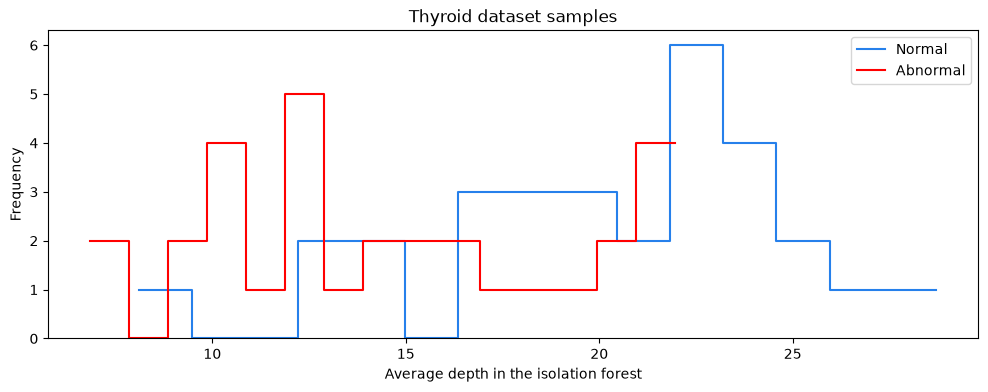

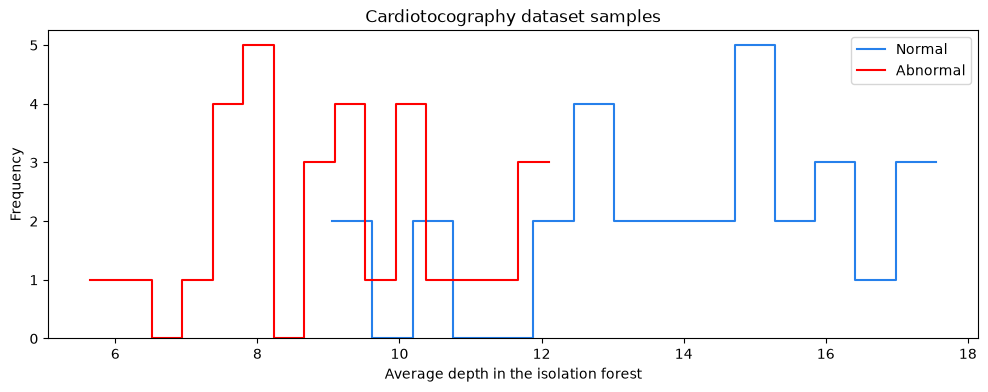

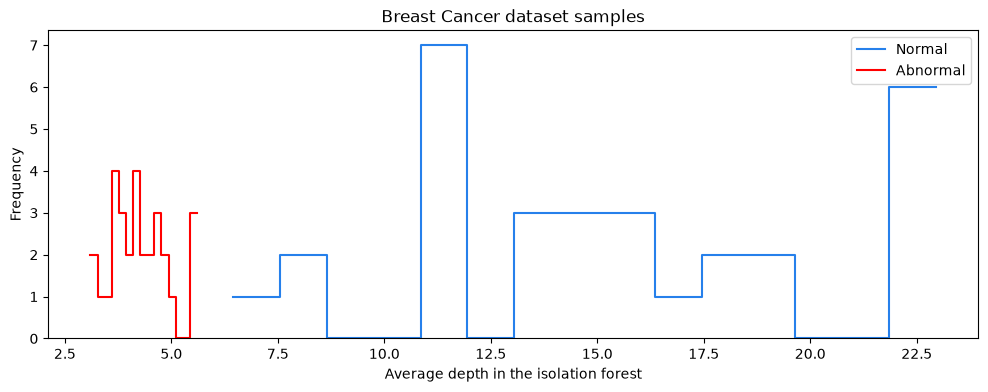

In [110]:
# LEAVE AS-IS

def plot_depth_histogram(normal_depths, abnormal_depths, dataset_name):
    plt.figure(figsize=(12,4))
    sns.histplot(normal_depths, label="Normal", bins=15, stat="count", element="step", fill=False, color="#2680EB")
    sns.histplot(abnormal_depths, label="Abnormal", bins=15, stat="count", element="step", fill=False, color="red")
    plt.title(f"{dataset_name} dataset samples")
    plt.xlabel("Average depth in the isolation forest")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

plot_depth_histogram(normal_depths_thyroid, abnormal_depths_thyroid, 'Thyroid')
plot_depth_histogram(normal_depths_cardio, abnormal_depths_cardio, 'Cardiotocography')
plot_depth_histogram(normal_depths_breastcancer, abnormal_depths_breastcancer, 'Breast Cancer')

<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Answer:**

What do you observe regarding the histograms of depths of normal and abnormal items in the three datasets? 

* Abnormal items generally have lower depths than normal items. This is more noticeable in Breast Cancer, while Thyroid and Cardiotocography have some overlap.

In which of the datasets there is more overlap? In which one there is less overlap?

* Thyroid has the most overlap, Cardiotocography has less, and Breast Cancer has the least overlap.

## 4.2. Compute outlier scores and conclude <font color="#2680EB">[10%]</font>

In [111]:
# LEAVE THIS CODE AS-IS
# Source: https://stackoverflow.com/a/27683292/1235784

from numpy import euler_gamma
from scipy.special import digamma
def harmonic(s):
    return digamma(s + 1) + euler_gamma

In [112]:
# LEAVE THIS CODE AS-IS

def outlier_score_factory(df):
    n = len(df.index)
    c_n = 2.0 * harmonic(n - 1.0) - (2.0 * (n-1)/n)
    return lambda d: 2.0**(-d/c_n)

outlier_score_thyroid = outlier_score_factory(dfti)
outlier_score_cardio = outlier_score_factory(dfci)
outlier_score_breastcancer = outlier_score_factory(dfbi)

# Compute the scores for thyroid
normal_scores_thyroid = [outlier_score_thyroid(d) for d in normal_depths_thyroid]
abnormal_scores_thyroid = [outlier_score_thyroid(d) for d in abnormal_depths_thyroid]

# Compute the scores for cardio
normal_scores_cardio = [outlier_score_cardio(d) for d in normal_depths_cardio]
abnormal_scores_cardio = [outlier_score_cardio(d) for d in abnormal_depths_cardio]

# Compute the scores for breast cancer
normal_scores_breastcancer = [outlier_score_breastcancer(d) for d in normal_depths_breastcancer]
abnormal_scores_breastcancer = [outlier_score_breastcancer(d) for d in abnormal_depths_breastcancer]


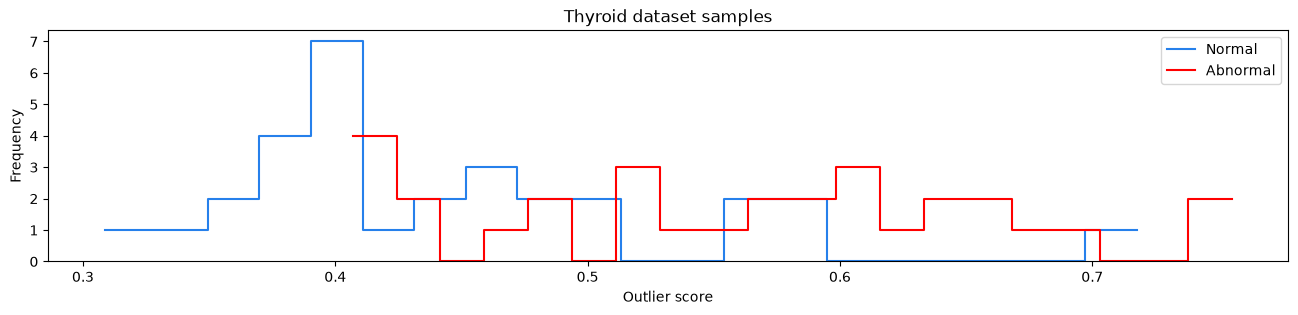

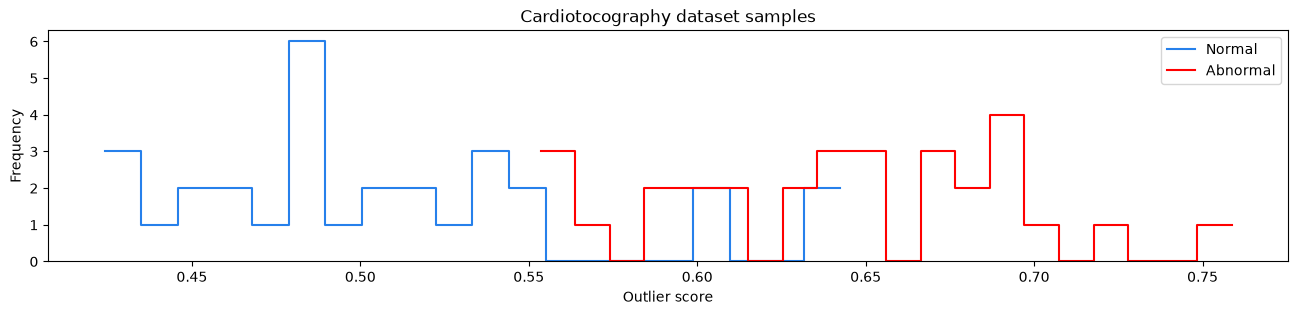

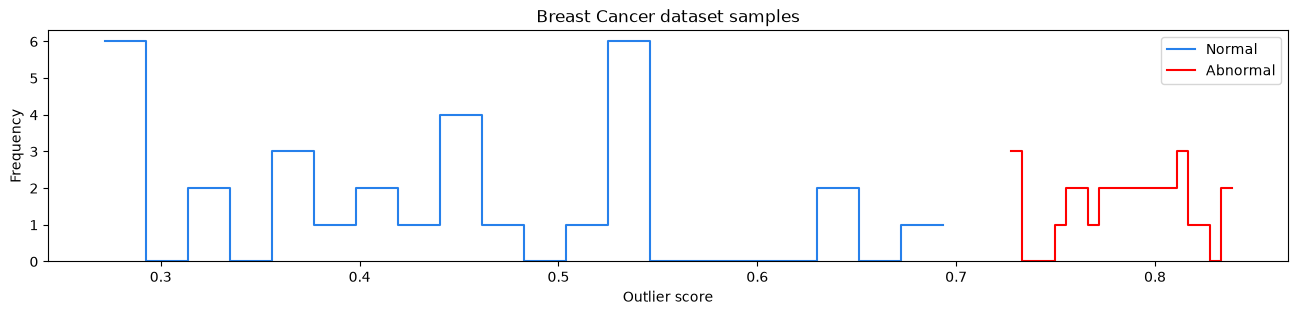

In [113]:
# LEAVE AS-IS

def plot_outlier_score_histogram(normal_scores, abnormal_scores, dataset_name):
    plt.figure(figsize=(16,3))
    sns.histplot(normal_scores, label="Normal", bins=20, stat="count", element="step", fill=False, color="#2680EB")
    sns.histplot(abnormal_scores, label="Abnormal", bins=20, stat="count", element="step", fill=False, color="red")
    plt.title(f"{dataset_name} dataset samples")
    plt.xlabel("Outlier score")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

plot_outlier_score_histogram(normal_scores_thyroid, abnormal_scores_thyroid, 'Thyroid')
plot_outlier_score_histogram(normal_scores_cardio, abnormal_scores_cardio, 'Cardiotocography')
plot_outlier_score_histogram(normal_scores_breastcancer, abnormal_scores_breastcancer, 'Breast Cancer')

<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Answer:**

What do you observe regarding the histograms of outlier scores in the three datasets? 

* Abnormal items generally have higher outlier scores than normal items. The separation is clearer in Breast Cancer, while Thyroid and Cardiotocography have more overlap.

How would you use it to **detect** outliers? 

* I would set a threshold for the outlier score. Items with a score above this threshold would be considered outliers.


<font size="+2" color="#2680EB">Additional results: faster method to find all depths</font>

In [114]:
def get_depths(tree, depth, results):
    if 'contents' in tree:
        for patient in tree['contents']['id']:
            results[patient] = depth
    else:
        get_depths(tree['left'], depth + 1, results)
        get_depths(tree['right'], depth + 1, results)

In [115]:
depths = {}
get_depths(mytree_thyroid, 0, depths)

print(depths)

{'P0020': 1, 'P0116': 1, 'P0117': 1, 'P0209': 1, 'P0290': 1, 'P0388': 1, 'P0518': 1, 'P0601': 1, 'P0687': 1, 'P0819': 1, 'P0861': 1, 'P1041': 1, 'P1043': 1, 'P1143': 1, 'P1213': 1, 'P1228': 1, 'P1269': 1, 'P1337': 1, 'P1377': 1, 'P1432': 1, 'P1466': 1, 'P1621': 1, 'P1634': 1, 'P1706': 1, 'P1707': 1, 'P1791': 1, 'P1883': 1, 'P2076': 1, 'P2137': 1, 'P2504': 1, 'P2512': 1, 'P2629': 1, 'P2703': 1, 'P2704': 1, 'P2775': 1, 'P2920': 1, 'P2932': 1, 'P3148': 1, 'P3165': 1, 'P3275': 1, 'P3276': 1, 'P3513': 1, 'P3551': 1, 'P3563': 1, 'P3570': 1, 'P3626': 1, 'P3783': 1, 'P3909': 1, 'P3944': 1, 'P3949': 1, 'P4008': 1, 'P4050': 1, 'P4077': 1, 'P4186': 1, 'P4302': 1, 'P4346': 1, 'P4420': 1, 'P4440': 1, 'P4480': 1, 'P4613': 1, 'P4672': 1, 'P4722': 1, 'P5125': 1, 'P5234': 1, 'P5311': 1, 'P5336': 1, 'P5377': 1, 'P5412': 1, 'P5463': 1, 'P5508': 1, 'P5558': 1, 'P5624': 1, 'P5862': 1, 'P5919': 1, 'P5957': 1, 'P6041': 1, 'P6159': 1, 'P6174': 1, 'P6374': 1, 'P6381': 1, 'P6470': 1, 'P6538': 1, 'P6702': 1, 'P6

In [116]:
# AI edited: AI helped me use the previous function for every tree,
# add each patient's depths and divide by the number of trees.

def average_depths(forest):
    totals = {}

    for tree in forest:
        depths = {}
        get_depths(tree, 0, depths)

        for patient in depths:
            if patient not in totals:
                totals[patient] = 0
            totals[patient] += depths[patient]

    for patient in totals:
        totals[patient] = totals[patient] / len(forest)

    return totals

In [143]:
def class_depths(df, forest, label):
    depths = average_depths(forest)
    return [depths[i] for i in df[df['result'] == label]['id']]

Thyroid: 6666 normal, 534 abnormal
Cardio: 1655 normal, 176 abnormal
Breast Cancer: 444 normal, 239 abnormal


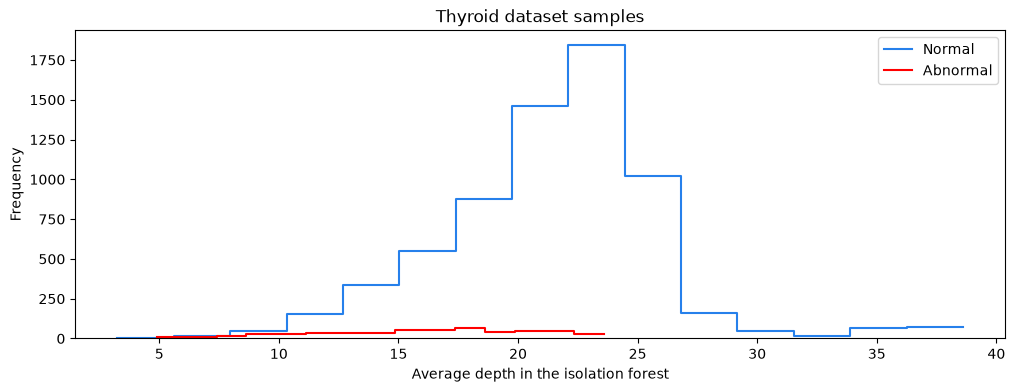

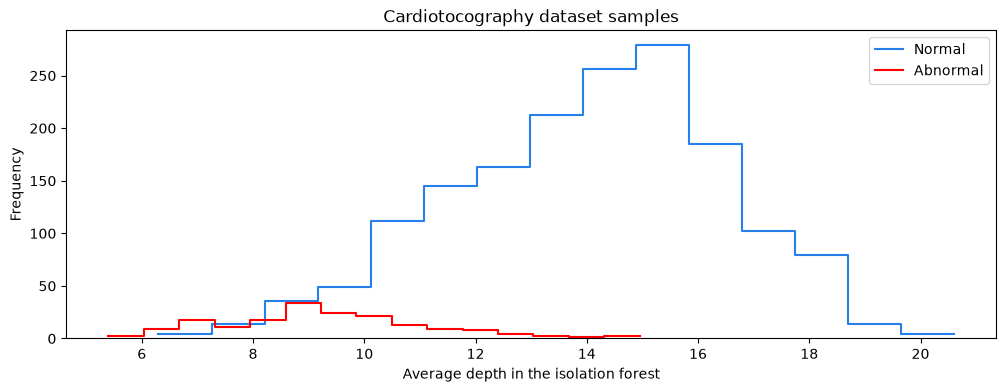

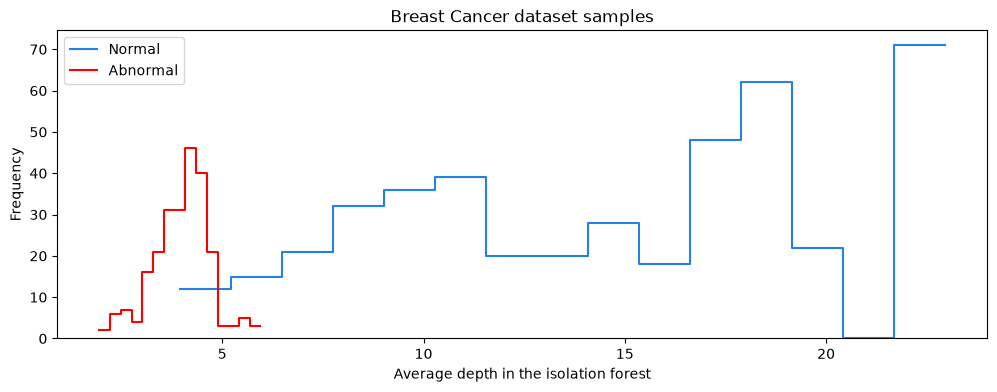

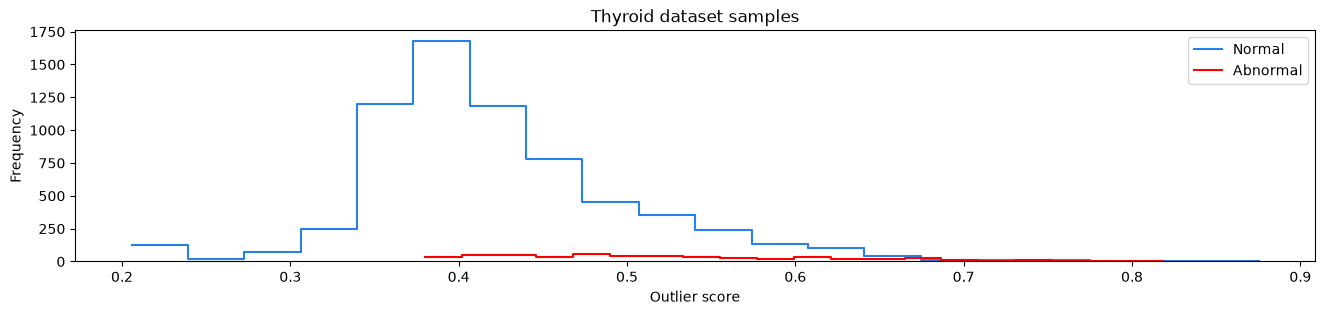

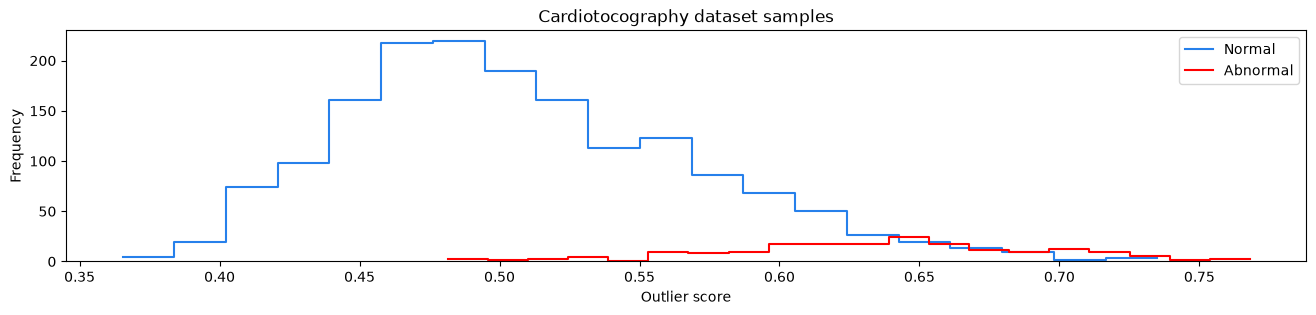

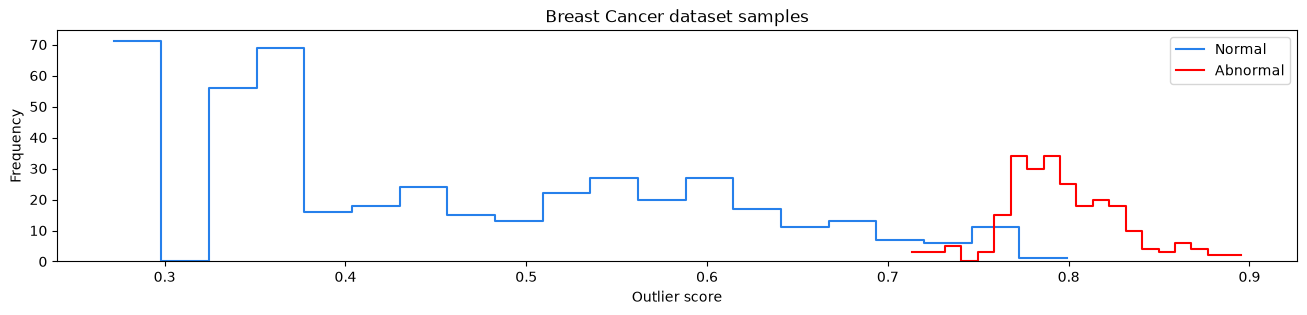

Thyroid scores: 7200
Cardio scores: 1831
Breast Cancer scores: 683


In [149]:
normal_depths_thyroid = class_depths(dfti, myforest_thyroid, 'normal')
abnormal_depths_thyroid = class_depths(dfti, myforest_thyroid, 'abnormal')

normal_depths_cardio = class_depths(dfci, myforest_cardio, 'normal')
abnormal_depths_cardio = class_depths(dfci, myforest_cardio, 'abnormal')

normal_depths_breastcancer = class_depths(dfbi, myforest_breastcancer, 'normal')
abnormal_depths_breastcancer = class_depths(dfbi, myforest_breastcancer, 'abnormal')

# AI: Recalculate outlier scores using the depths of all patients.
normal_scores_thyroid = [outlier_score_thyroid(d) for d in normal_depths_thyroid]
abnormal_scores_thyroid = [outlier_score_thyroid(d) for d in abnormal_depths_thyroid]

normal_scores_cardio = [outlier_score_cardio(d) for d in normal_depths_cardio]
abnormal_scores_cardio = [outlier_score_cardio(d) for d in abnormal_depths_cardio]

normal_scores_breastcancer = [outlier_score_breastcancer(d) for d in normal_depths_breastcancer]
abnormal_scores_breastcancer = [outlier_score_breastcancer(d) for d in abnormal_depths_breastcancer]

print("Thyroid:", len(normal_depths_thyroid), "normal,", len(abnormal_depths_thyroid), "abnormal")
print("Cardio:", len(normal_depths_cardio), "normal,", len(abnormal_depths_cardio), "abnormal")
print("Breast Cancer:", len(normal_depths_breastcancer), "normal,", len(abnormal_depths_breastcancer), "abnormal")

# AI: Used the previous functions to plot the depths of all patients instead of samples.
plot_depth_histogram(normal_depths_thyroid, abnormal_depths_thyroid, 'Thyroid')
plot_depth_histogram(normal_depths_cardio, abnormal_depths_cardio, 'Cardiotocography')
plot_depth_histogram(normal_depths_breastcancer, abnormal_depths_breastcancer, 'Breast Cancer')

# AI: Used the outlier scores to plot the results for the three complete datasets.
plot_outlier_score_histogram(normal_scores_thyroid, abnormal_scores_thyroid, 'Thyroid')
plot_outlier_score_histogram(normal_scores_cardio, abnormal_scores_cardio, 'Cardiotocography')
plot_outlier_score_histogram(normal_scores_breastcancer, abnormal_scores_breastcancer, 'Breast Cancer')


print("Thyroid scores:", len(normal_scores_thyroid) + len(abnormal_scores_thyroid))
print("Cardio scores:", len(normal_scores_cardio) + len(abnormal_scores_cardio))
print("Breast Cancer scores:", len(normal_scores_breastcancer) + len(abnormal_scores_breastcancer))

**Additional results: Faster method to find all depths**

I implemented a faster method to calculate the average depths by going through each tree only once. I used all patients instead of random samples. The results show that abnormal patients generally have lower depths and higher outlier scores, especially in Breast Cancer.

<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that my answers were not written by an AI-enabled code assistant, and that except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>